# `tl.interaction_changed_genes` vs a per-gene `scipy.stats` + `statsmodels` loop

For every (receiver cell type, neighbor cell type) pair, `interaction_changed_genes` tests whether "contacted" cells (>=1 spatial neighbor of the given type) differ in expression from non-contacted cells of the same type - a two-group differential-expression test vectorized across every gene at once, instead of looping `scipy.stats` per gene. This notebook checks that vectorized reimplementation against a plain per-gene loop over `scipy.stats.mannwhitneyu`/`ttest_ind` and `statsmodels.stats.multitest.multipletests`.

In [1]:
import logging
logging.basicConfig(level=logging.INFO)

import time
import numpy as np
import pandas as pd
import astrolabe as ab
from scipy.stats import mannwhitneyu, ttest_ind
from statsmodels.stats.multitest import multipletests


INFO:astrolabe.pl._theme:Registered bundled Inter font files with matplotlib


INFO:astrolabe.pl._theme:astrolabe plot theme set to 'light'


## Dataset

`ab.datasets.xenium_tiny()` with Leiden clusters as cell types and a spatial
graph to define "contact."


In [2]:
mdata = ab.datasets.xenium_tiny()
ab.pipeline.filter_xenium(mdata)
ab.pp.normalize_total(mdata)
ab.pp.log1p(mdata)
ab.pp.highly_variable_genes(mdata)
ab.tl.pca(mdata)
ab.tl.transcriptional_neighbors(mdata)
ab.tl.cluster(mdata, resolution=0.5)
ab.tl.spatial_neighbors(mdata)

adata = mdata["xenium"]
adata


INFO:astrolabe.io._xenium:Reading Xenium run 'outs' from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\scipy_stats\.astrolabe_cache\datasets\xenium_tiny\outs


C:\Users\Austin\PycharmProjects\astrolabe\astrolabe\io\_xenium.py:870: ExperimentalFeatureWarning: Support for Awkward Arrays is currently experimental. Behavior may change in the future. Please report any issues you may encounter!
  adata.obsm[obsm_key] = ak.Array(
INFO:astrolabe.io._xenium:Loaded 358 cells × 520 features (115 control probes)


INFO:astrolabe.io._xenium:Streaming transcripts from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\scipy_stats\.astrolabe_cache\datasets\xenium_tiny\outs\transcripts.parquet


INFO:astrolabe.io._xenium:Loaded 20999 transcript detections


INFO:astrolabe.pipeline:filter_xenium: 358 cells × 520 genes


...

INFO:astrolabe.pipeline:filter_xenium: done — 328 cells × 255 genes


INFO:astrolabe.tl._graph:transcriptional_neighbors: 328 cells -> uns['neighbors']


INFO:astrolabe.tl._cluster:cluster (leiden, res=0.50): 4 clusters


INFO:astrolabe.tl._graph:spatial_neighbors: 328 cells, 5670 edges (mean degree 17.3) [generic]


AnnData object with n_obs × n_vars = 328 × 255
    obs: 'cell_area', 'nucleus_area', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'nucleus_count', 'unassigned_codeword_total', 'deprecated_codeword_total', 'genomic_control_probe_total', 'negative_control_codeword_total', 'negative_control_probe_total', 'any_negative_control_probe_total', 'n_unassigned_codewords', 'n_deprecated_codewords', 'n_genomic_control_probes', 'n_negative_control_codewords', 'n_negative_control_probes', 'n_any_negative_control_probes', 'pct_unassigned_codewords', 'pct_deprecated_codewords', 'pct_genomic_control_probes', 'pct_negative_control_codewords', 'pct_negative_control_probes', 'pct_any_negative_control_probes', 'pct_counts_control', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'nucleus_to_cell_area_ratio', 'has_nucleus', 'total_counts_norm', 'leiden'

## Astrolabe: `tl.interaction_changed_genes`


In [3]:
_t0 = time.perf_counter()
icg_astro = ab.tl.interaction_changed_genes(
    mdata, groupby="leiden", method="wilcoxon", fdr_scope="pair",
)
t_astro_s = time.perf_counter() - _t0
print(f"astrolabe runtime: {t_astro_s:.4f}s")
icg_astro.head()


INFO:astrolabe.tl._icg:ICG [1 | nb=0]: 40 vs 14 cells


INFO:astrolabe.tl._icg:ICG [2 | nb=0]: 73 vs 31 cells


INFO:astrolabe.tl._icg:ICG [2 | nb=3]: 71 vs 33 cells


INFO:astrolabe.tl._icg:ICG [3 | nb=0]: 110 vs 30 cells


INFO:astrolabe.tl._icg:ICG [3 | nb=1]: 61 vs 79 cells


INFO:astrolabe.tl._icg:ICG [3 | nb=2]: 93 vs 47 cells


INFO:astrolabe.tl._icg:interaction_changed_genes: 1530 rows across 6 tested pairs


astrolabe runtime: 0.1589s


,cell_type,neighbor_type,gene,statistic,pval,mean_contacted,mean_non_contacted,log2fc,n_contacted,n_non_contacted,pval_adj
0,1,0,VCAN,110.5,0.000285,0.383819,1.286866,-2.056608,40,14,0.072709
1,1,0,S100A12,220.0,0.003094,0.000000,0.124212,-27.339639,40,14,0.394472
2,1,0,HLA-DRB5,161.5,0.005498,0.157319,0.464118,-1.601986,40,14,0.467372
3,1,0,CD300E,183.0,0.008858,0.186966,0.529332,-1.442169,40,14,0.564691
4,1,0,ITGAX,179.0,0.013995,0.228343,0.611608,-1.299424,40,14,0.598941


## Reference: the identical contacted/non-contacted split, tested with plain `scipy.stats`

Reproduces the same contact split astrolabe computes (any nonzero connectivity weight from a receiver cell to a neighbor-type cell counts as "contacted"), then runs `scipy.stats.mannwhitneyu` per gene with `method='asymptotic'` and continuity correction to match astrolabe's own implementation, and `statsmodels`'s Benjamini-Hochberg correction per pair to match `fdr_scope='pair'`.

One edge case needs explicit handling: for a gene that's constant (e.g. all zero) across both groups combined, the Mann-Whitney normal approximation has zero variance and plain `scipy.stats.mannwhitneyu` returns `nan`. Astrolabe guards this case and reports `pval=1.0` instead, so the reference loop applies the same guard to match.

In [4]:
categories = adata.obs["leiden"].cat.categories.tolist()
conn = adata.obsp["spatial_neighbors_connectivities"]
X = np.asarray(adata.X.toarray() if hasattr(adata.X, "toarray") else adata.X, dtype=np.float64)
gene_names = list(adata.var_names)
codes = adata.obs["leiden"].cat.codes.to_numpy()
type_idx = {ct: np.where(codes == i)[0] for i, ct in enumerate(categories)}

_t0 = time.perf_counter()
rows = []
for ct_a in categories:
    idx_a = type_idx[ct_a]
    conn_a = conn[idx_a, :]
    for ct_b in categories:
        idx_b = type_idx[ct_b]
        if len(idx_b) == 0:
            continue
        neighbor_counts = np.asarray(conn_a[:, idx_b].sum(axis=1)).ravel()
        local_cont = np.where(neighbor_counts > 0)[0]
        local_non = np.where(neighbor_counts == 0)[0]
        if len(local_cont) < 10 or len(local_non) < 10:
            continue

        X_cont = X[idx_a[local_cont], :]
        X_non = X[idx_a[local_non], :]

        pvals = np.empty(len(gene_names))
        for g in range(len(gene_names)):
            col_cont, col_non = X_cont[:, g], X_non[:, g]
            if np.ptp(np.concatenate([col_cont, col_non])) == 0:
                # Zero-variance combined column: matches astrolabe's own
                # sigma > 0 guard rather than propagating scipy's nan.
                pvals[g] = 1.0
            else:
                _, p = mannwhitneyu(
                    col_cont, col_non,
                    method="asymptotic", use_continuity=True,
                )
                pvals[g] = p
        pvals_adj = multipletests(pvals, method="fdr_bh")[1]

        for g, gene in enumerate(gene_names):
            rows.append({
                "cell_type": ct_a, "neighbor_type": ct_b, "gene": gene,
                "pval_ref": pvals[g], "pval_adj_ref": pvals_adj[g],
            })

t_ref_s = time.perf_counter() - _t0
print(f"reference runtime: {t_ref_s:.4f}s")

icg_ref = pd.DataFrame(rows)
icg_ref.head()


reference runtime: 0.5776s


,cell_type,neighbor_type,gene,pval_ref,pval_adj_ref
0,1,0,ACKR1,0.017184,0.598941
1,1,0,ACTA2,0.020470,0.598941
2,1,0,ACTG2,0.023804,0.598941
3,1,0,ADAM28,0.930724,1.000000
4,1,0,ADAMTS1,0.930724,1.000000


## Agreement


Pearson r (-log10 pval) = 1.000000
max |pval_adj - reference pval_adj| = 2.22e-16
Runtime: astrolabe 0.1589s vs per-gene scipy loop 0.5776s (3.6x astrolabe faster)


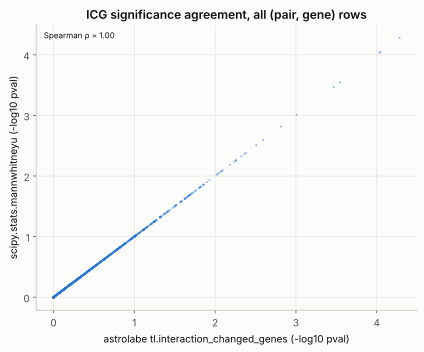

In [5]:
merged = icg_astro.merge(icg_ref, on=["cell_type", "neighbor_type", "gene"])

# pvals can be exactly 0 in floating point (deep in the tail of the normal
# approximation); clip before -log10 so the comparison isn't dominated by a
# handful of -inf/+inf outliers that both sides agree are "very significant."
eps = 1e-300
neglog_astro = -np.log10(np.clip(merged["pval"], eps, 1.0))
neglog_ref = -np.log10(np.clip(merged["pval_ref"], eps, 1.0))

r = np.corrcoef(neglog_astro, neglog_ref)[0, 1]
adj_max_diff = float((merged["pval_adj"] - merged["pval_adj_ref"]).abs().max())
print(f"Pearson r (-log10 pval) = {r:.6f}")
print(f"max |pval_adj - reference pval_adj| = {adj_max_diff:.2e}")
print(f"Runtime: astrolabe {t_astro_s:.4f}s vs per-gene scipy loop {t_ref_s:.4f}s "
      f"({max(t_astro_s, t_ref_s) / min(t_astro_s, t_ref_s):.1f}x astrolabe {'faster' if t_astro_s < t_ref_s else 'slower'})")

panel = ab.pl.scatter(
    adata, x=neglog_astro.to_numpy(), y=neglog_ref.to_numpy(), annotate_corr=True,
    xlabel="astrolabe tl.interaction_changed_genes (-log10 pval)",
    ylabel="scipy.stats.mannwhitneyu (-log10 pval)",
    title="ICG significance agreement, all (pair, gene) rows",
)
panel.show()


## Interpretation

Both sides run the identical asymptotic, tie-corrected, continuity-corrected Mann-Whitney U test on the identical contacted/non-contacted split, so raw p-values should land on `y = x` to floating-point precision and BH-adjusted p-values should match exactly (a deterministic sort-and-scale procedure with no room for numerical divergence). A real gap here would most likely mean the contact definition (`conn_a[:, idx_b].sum(axis=1) > 0`) isn't being replicated exactly, not a divergence in the underlying statistics.